In [1]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from urllib.request import urlretrieve
from zipfile import ZipFile
%matplotlib inline

In [2]:
def download_and_unzip(url, save_path):
    print(f"Downloading and extracting assests....", end="")

    # Downloading zip file using urllib package.
    urlretrieve(url, save_path)

    try:
        # Extracting zip file using the zipfile package.
        with ZipFile(save_path) as z:
            # Extract ZIP file contents in the same directory.
            z.extractall(os.path.split(save_path)[0])

        print("Done")

    except Exception as e:
        print("\nInvalid file.", e)

In [3]:
URL = r" https://www.kaggle.com/api/v1/datasets/download/mitishaagarwal/patient"

asset_zip_path = os.path.join(os.getcwd(), f"patient.zip")

# Download if assest ZIP does not exists. 
if not os.path.exists(asset_zip_path):
    download_and_unzip(URL, asset_zip_path) 

In [4]:
num_cols = [
    # Demographics & Pre-ICU
    'age', 'bmi', 'pre_icu_los_days',
    # Hemodynamics & Vitals
    'd1_heartrate_max', 'd1_sysbp_min', 'd1_diasbp_min',
    'resprate_apache', 'temp_apache', 'd1_spo2_min',
    # Metabolic & Electrolytes
    'd1_glucose_max', 'd1_glucose_min',
    'd1_potassium_max', 'd1_potassium_min',
    # Neurological (Complete GCS) & Life Support
    'gcs_eyes_apache', 'gcs_motor_apache', 'gcs_verbal_apache',
    'ventilated_apache',
    #Intubation
    'intubated_apache'
    
]

cat_cols = ['gender', 'icu_admit_source', 'apache_3j_bodysystem']
target_col = 'hospital_death'

selected_cols = num_cols + cat_cols + [target_col]


df = pd.read_csv("dataset.csv", usecols=selected_cols)


ex_data = df.copy()
ex_data.head()


,age,bmi,gender,icu_admit_source,pre_icu_los_days,gcs_eyes_apache,gcs_motor_apache,gcs_verbal_apache,intubated_apache,resprate_apache,...,d1_diasbp_min,d1_heartrate_max,d1_spo2_min,d1_sysbp_min,d1_glucose_max,d1_glucose_min,d1_potassium_max,d1_potassium_min,apache_3j_bodysystem,hospital_death
0,68.0,22.73,M,Floor,0.541667,3.0,6.0,4.0,0.0,36.0,...,37.0,119.0,74.0,73.0,168.0,109.0,4.0,3.4,Sepsis,0
1,77.0,27.42,F,Floor,0.927778,1.0,3.0,1.0,0.0,33.0,...,31.0,118.0,70.0,67.0,145.0,128.0,4.2,3.8,Respiratory,0
2,25.0,31.95,F,Accident & Emergency,0.000694,3.0,6.0,5.0,0.0,37.0,...,48.0,96.0,91.0,105.0,NaN,NaN,NaN,NaN,Metabolic,0
3,81.0,22.64,F,Operating Room / Recovery,0.000694,4.0,6.0,5.0,1.0,4.0,...,42.0,116.0,95.0,84.0,185.0,88.0,5.0,3.5,Cardiovascular,0
4,19.0,NaN,M,Accident & Emergency,0.073611,NaN,NaN,NaN,0.0,16.0,...,57.0,89.0,96.0,120.0,NaN,NaN,NaN,NaN,Trauma,0


## EXPLORATORAY DATA ANALYSIS

In [6]:
ex_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91713 entries, 0 to 91712
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   87485 non-null  float64
 1   bmi                   88284 non-null  float64
 2   gender                91688 non-null  object 
 3   icu_admit_source      91601 non-null  object 
 4   pre_icu_los_days      91713 non-null  float64
 5   gcs_eyes_apache       89812 non-null  float64
 6   gcs_motor_apache      89812 non-null  float64
 7   gcs_verbal_apache     89812 non-null  float64
 8   intubated_apache      90998 non-null  float64
 9   resprate_apache       90479 non-null  float64
 10  temp_apache           87605 non-null  float64
 11  ventilated_apache     90998 non-null  float64
 12  d1_diasbp_min         91548 non-null  float64
 13  d1_heartrate_max      91568 non-null  float64
 14  d1_spo2_min           91380 non-null  float64
 15  d1_sysbp_min       

In [7]:
ex_data.isnull().sum()

age                     4228
bmi                     3429
gender                    25
icu_admit_source         112
pre_icu_los_days           0
gcs_eyes_apache         1901
gcs_motor_apache        1901
gcs_verbal_apache       1901
intubated_apache         715
resprate_apache         1234
temp_apache             4108
ventilated_apache        715
d1_diasbp_min            165
d1_heartrate_max         145
d1_spo2_min              333
d1_sysbp_min             159
d1_glucose_max          5807
d1_glucose_min          5807
d1_potassium_max        9585
d1_potassium_min        9585
apache_3j_bodysystem    1662
hospital_death             0
dtype: int64

In [8]:
ex_data.shape

(91713, 22)

In [9]:
ex_data.describe()

,age,bmi,pre_icu_los_days,gcs_eyes_apache,gcs_motor_apache,gcs_verbal_apache,intubated_apache,resprate_apache,temp_apache,ventilated_apache,d1_diasbp_min,d1_heartrate_max,d1_spo2_min,d1_sysbp_min,d1_glucose_max,d1_glucose_min,d1_potassium_max,d1_potassium_min,hospital_death
count,87485.000000,88284.000000,91713.000000,89812.000000,89812.000000,89812.000000,90998.000000,90479.000000,87605.000000,90998.000000,91548.000000,91568.000000,91380.000000,91554.00000,85906.000000,85906.000000,82128.000000,82128.000000,91713.000000
mean,62.309516,29.185818,0.835766,3.465049,5.471195,3.994778,0.151223,25.811007,36.414472,0.325721,50.161314,103.000568,90.454826,96.92387,174.638023,114.380940,4.251594,3.934658,0.086302
std,16.775119,8.275142,2.487756,0.951715,1.288376,1.560166,0.358268,15.106312,0.833496,0.468646,13.317586,22.017346,10.030069,20.67793,86.687955,38.273013,0.667355,0.579610,0.280811
min,16.000000,14.844926,-24.947222,1.000000,1.000000,1.000000,0.000000,4.000000,32.100000,0.000000,13.000000,58.000000,0.000000,41.00000,73.000000,33.000000,2.800000,2.400000,0.000000
25%,52.000000,23.641975,0.035417,3.000000,6.000000,4.000000,0.000000,11.000000,36.200000,0.000000,42.000000,87.000000,89.000000,83.00000,117.000000,91.000000,3.800000,3.600000,0.000000
50%,65.000000,27.654655,0.138889,4.000000,6.000000,5.000000,0.000000,28.000000,36.500000,0.000000,50.000000,101.000000,92.000000,96.00000,150.000000,107.000000,4.200000,3.900000,0.000000
75%,75.000000,32.930206,0.409028,4.000000,6.000000,5.000000,0.000000,36.000000,36.700000,1.000000,58.000000,116.000000,95.000000,110.00000,201.000000,131.000000,4.600000,4.300000,0.000000
max,89.000000,67.814990,159.090972,4.000000,6.000000,5.000000,1.000000,60.000000,39.700000,1.000000,90.000000,177.000000,100.000000,160.00000,611.000000,288.000000,7.000000,5.800000,1.000000


In [10]:
ex_data['hospital_death'].value_counts() / len(ex_data)

hospital_death
0    0.913698
1    0.086302
Name: count, dtype: float64

In [11]:
ex_data["gender"].value_counts()

gender
M    49469
F    42219
Name: count, dtype: int64

In [12]:
ex_data["icu_admit_source"].value_counts()

icu_admit_source
Accident & Emergency         54060
Operating Room / Recovery    18713
Floor                        15611
Other Hospital                2358
Other ICU                      859
Name: count, dtype: int64

In [13]:
ex_data["apache_3j_bodysystem"].value_counts()

apache_3j_bodysystem
Cardiovascular          29999
Neurological            11896
Sepsis                  11740
Respiratory             11609
Gastrointestinal         9026
Metabolic                7650
Trauma                   3842
Genitourinary            2172
Musculoskeletal/Skin     1166
Hematological             638
Gynecological             313
Name: count, dtype: int64

## Missing Data Handling

In [15]:
num_cols = ex_data.select_dtypes(include=['number']).columns
cat_cols = ex_data.select_dtypes(include=['object']).columns

ex_data[num_cols] = ex_data[num_cols].fillna(ex_data[num_cols].median())
ex_data[cat_cols] = ex_data[cat_cols].fillna(ex_data[cat_cols].mode().iloc[0])

ex_data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 91713 entries, 0 to 91712
Data columns (total 22 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   age                   91713 non-null  float64
 1   bmi                   91713 non-null  float64
 2   gender                91713 non-null  object 
 3   icu_admit_source      91713 non-null  object 
 4   pre_icu_los_days      91713 non-null  float64
 5   gcs_eyes_apache       91713 non-null  float64
 6   gcs_motor_apache      91713 non-null  float64
 7   gcs_verbal_apache     91713 non-null  float64
 8   intubated_apache      91713 non-null  float64
 9   resprate_apache       91713 non-null  float64
 10  temp_apache           91713 non-null  float64
 11  ventilated_apache     91713 non-null  float64
 12  d1_diasbp_min         91713 non-null  float64
 13  d1_heartrate_max      91713 non-null  float64
 14  d1_spo2_min           91713 non-null  float64
 15  d1_sysbp_min       

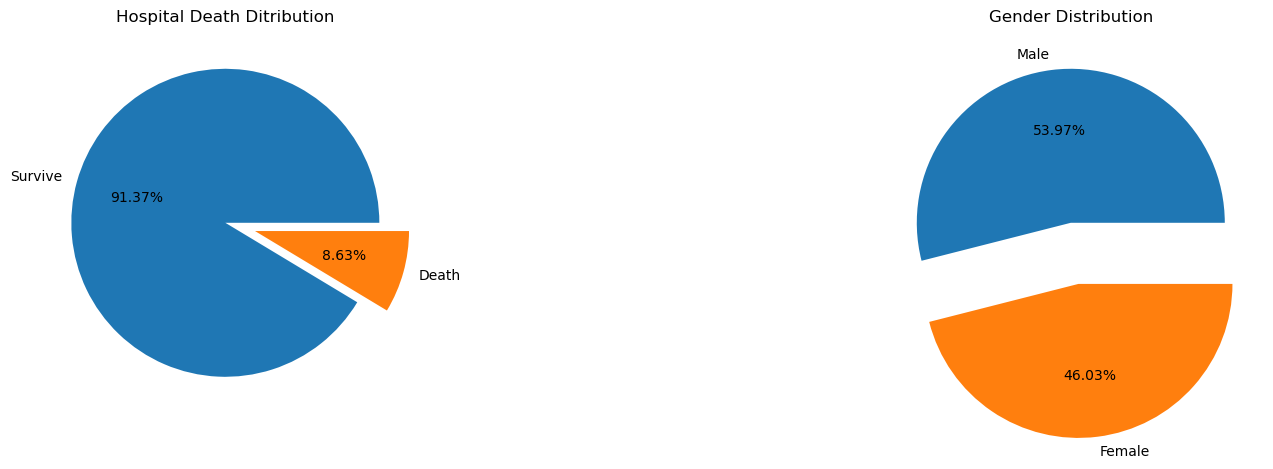

In [16]:
hospital_deaths = ex_data['hospital_death'].value_counts()
gender = ex_data["gender"].value_counts()

plt.figure(figsize=[20,5])
plt.subplot(121);plt.pie(hospital_deaths, autopct='%0.2f%%', explode= [0,0.2], labels=["Survive", "Death"]);plt.title("Hospital Death Ditribution")
plt.subplot(122); plt.pie(gender, autopct='%0.2f%%', explode= [0,0.4], labels=["Male", "Female"]);plt.title("Gender Distribution")
#plt.pie(hospital_deaths, autopct='%0.2f%%', explode= [0,0.2], labels=["Survive", "Death"])
plt.show()

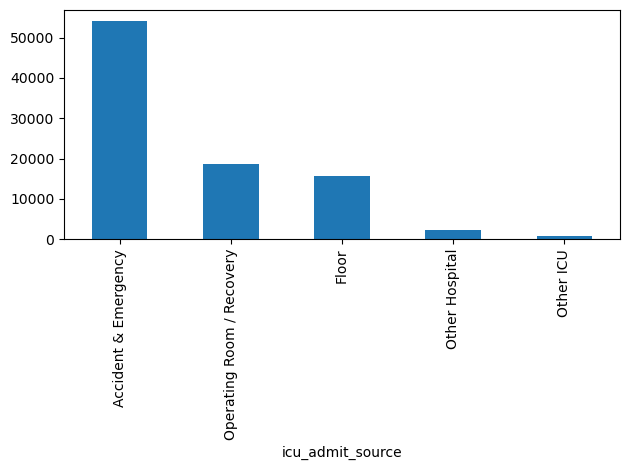

In [17]:
ex_data['icu_admit_source'].value_counts().plot.bar()
plt.tight_layout()
plt.show()

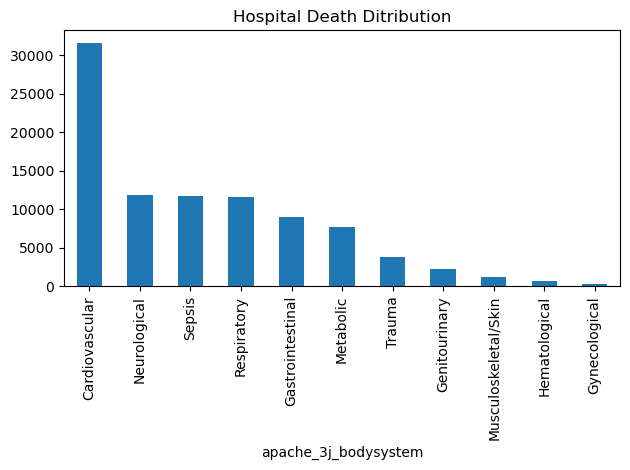

In [18]:
ex_data["apache_3j_bodysystem"].value_counts().plot.bar();plt.title("Hospital Death Ditribution")
plt.tight_layout()
plt.show()

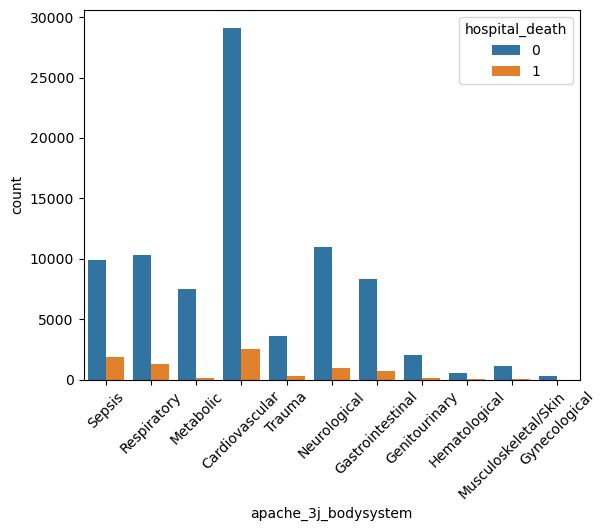

In [19]:
sns.countplot(x="apache_3j_bodysystem", data= ex_data, hue= "hospital_death")
plt.xticks(rotation=45)
plt.show()

## Establishing the Holdout Set

In [38]:
# Create an initial random holdout split for comparison with stratified sampling.
from sklearn.model_selection import train_test_split
train_set, test_set = train_test_split(ex_data, test_size = 0.2, random_state = 42)

test_set.shape

(18343, 22)

In [39]:
train_set["hospital_death"].value_counts() / len(train_set)

hospital_death
0    0.913752
1    0.086248
Name: count, dtype: float64

## Stratified Train–Test Split

In [41]:
"""
# Preserve the observed hospital death -count proportions in both partitions.
from sklearn.model_selection import StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits = 1, test_size = 0.2, random_state = 42)
for train_index, test_index in split.split(ex_data, ex_data["hospital_death"]):
    strat_train_set = ex_data.loc[train_index]
    strat_test_set = ex_data.loc[test_index]

strat_test_set.shape
"""

'\n# Preserve the observed hospital death -count proportions in both partitions.\nfrom sklearn.model_selection import StratifiedShuffleSplit\nsplit = StratifiedShuffleSplit(n_splits = 1, test_size = 0.2, random_state = 42)\nfor train_index, test_index in split.split(ex_data, ex_data["hospital_death"]):\n    strat_train_set = ex_data.loc[train_index]\n    strat_test_set = ex_data.loc[test_index]\n\nstrat_test_set.shape\n'

In [42]:
from sklearn.model_selection import StratifiedShuffleSplit
split = StratifiedShuffleSplit(n_splits = 1, test_size = 0.2, random_state = 42)
for train_index, test_index in split.split(df, df["hospital_death"]):
    strat_train_set = df.loc[train_index]
    strat_test_set = df.loc[test_index]

strat_test_set.shape

(18343, 22)

In [43]:
strat_test_set["hospital_death"].value_counts()/ len(strat_test_set)

hospital_death
0    0.9137
1    0.0863
Name: count, dtype: float64

In [44]:
strat_train_set['hospital_death'].value_counts() / len(strat_train_set)

hospital_death
0    0.913698
1    0.086302
Name: count, dtype: float64

## Correlation Analysis

In [46]:
train_data = strat_train_set.copy()
for col in train_data.select_dtypes(include='object').columns:
    train_data[col] = train_data[col].astype("category").cat.codes

In [47]:
# Rank the training-set features by their linear correlation with the Hospital death target.
corr_matrix = train_data.corr()
corr_matrix["hospital_death"].sort_values(ascending = False) 

hospital_death          1.000000
ventilated_apache       0.227051
intubated_apache        0.172766
d1_heartrate_max        0.161828
age                     0.112253
d1_potassium_max        0.111843
resprate_apache         0.086009
d1_glucose_max          0.079084
pre_icu_los_days        0.062964
apache_3j_bodysystem    0.056697
d1_potassium_min        0.027799
d1_glucose_min          0.027616
gender                 -0.008666
icu_admit_source       -0.022080
bmi                    -0.033540
temp_apache            -0.152868
d1_diasbp_min          -0.179945
d1_spo2_min            -0.206596
d1_sysbp_min           -0.209072
gcs_verbal_apache      -0.239663
gcs_eyes_apache        -0.257315
gcs_motor_apache       -0.276914
Name: hospital_death, dtype: float64

## Feature Engineering Exploratiom

In [49]:
train_data["shock_index"] = train_data["d1_heartrate_max"] / (train_data["d1_sysbp_min"] + 1e-5)
train_data["pulse_pressure"] = train_data["d1_sysbp_min"] - train_data["d1_diasbp_min"]
train_data["gcs_total"] = train_data["gcs_eyes_apache"] + train_data["gcs_motor_apache"] + train_data["gcs_verbal_apache"] 
train_data["glucose_swing"] = train_data["d1_glucose_max"] - train_data["d1_glucose_min"]
train_data["potassium_swing"] = train_data["d1_potassium_max"] - train_data["d1_potassium_min"]
train_data["cardio_resp_stress"] = ((train_data["d1_heartrate_max"] * train_data["resprate_apache"]) / (train_data["d1_spo2_min"] + 1.0))

corr_matrix = train_data.corr()
corr_matrix["hospital_death"].sort_values(ascending = False)

hospital_death          1.000000
shock_index             0.278751
ventilated_apache       0.227051
intubated_apache        0.172766
d1_heartrate_max        0.161828
age                     0.112253
d1_potassium_max        0.111843
potassium_swing         0.109316
resprate_apache         0.086009
d1_glucose_max          0.079084
cardio_resp_stress      0.076855
glucose_swing           0.072234
pre_icu_los_days        0.062964
apache_3j_bodysystem    0.056697
d1_potassium_min        0.027799
d1_glucose_min          0.027616
gender                 -0.008666
icu_admit_source       -0.022080
bmi                    -0.033540
pulse_pressure         -0.124781
temp_apache            -0.152868
d1_diasbp_min          -0.179945
d1_spo2_min            -0.206596
d1_sysbp_min           -0.209072
gcs_verbal_apache      -0.239663
gcs_eyes_apache        -0.257315
gcs_motor_apache       -0.276914
gcs_total              -0.280541
Name: hospital_death, dtype: float64

In [50]:
# Separate predictors from the continuous MPG target using the stratified training partition.

data = strat_train_set.drop("hospital_death", axis=1)
data_labels = strat_train_set["hospital_death"].copy()
data

,age,bmi,gender,icu_admit_source,pre_icu_los_days,gcs_eyes_apache,gcs_motor_apache,gcs_verbal_apache,intubated_apache,resprate_apache,...,ventilated_apache,d1_diasbp_min,d1_heartrate_max,d1_spo2_min,d1_sysbp_min,d1_glucose_max,d1_glucose_min,d1_potassium_max,d1_potassium_min,apache_3j_bodysystem
59226,72.0,32.041330,F,Floor,0.061111,4.0,6.0,4.0,0.0,13.0,...,0.0,13.0,150.0,38.0,48.0,132.0,107.0,4.1,4.1,Sepsis
81334,58.0,34.334291,M,Accident & Emergency,0.032639,1.0,1.0,1.0,0.0,53.0,...,1.0,14.0,138.0,81.0,77.0,319.0,212.0,4.3,4.1,Sepsis
67173,78.0,32.764004,F,Operating Room / Recovery,2.527083,3.0,6.0,5.0,0.0,12.0,...,0.0,44.0,70.0,91.0,104.0,115.0,115.0,4.4,4.4,Neurological
50977,65.0,32.992135,M,Accident & Emergency,0.122917,4.0,6.0,5.0,0.0,NaN,...,0.0,59.0,103.0,95.0,102.0,153.0,128.0,4.5,4.0,Cardiovascular
43831,45.0,20.381570,M,Accident & Emergency,0.054167,3.0,6.0,3.0,1.0,11.0,...,1.0,54.0,113.0,81.0,82.0,156.0,156.0,3.8,3.8,Respiratory
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
15444,82.0,NaN,M,Floor,3.011111,4.0,6.0,5.0,0.0,32.0,...,0.0,48.0,65.0,96.0,85.0,181.0,135.0,4.3,4.3,Neurological
85478,64.0,32.553708,M,Accident & Emergency,0.007639,4.0,6.0,5.0,0.0,57.0,...,0.0,55.0,90.0,94.0,92.0,184.0,126.0,3.7,3.7,Cardiovascular
7726,56.0,NaN,M,Accident & Emergency,0.005556,4.0,6.0,5.0,0.0,29.0,...,0.0,55.0,102.0,95.0,107.0,110.0,110.0,3.8,3.8,Respiratory
21627,27.0,27.476316,M,Accident & Emergency,0.004167,4.0,6.0,5.0,0.0,6.0,...,0.0,51.0,108.0,97.0,95.0,422.0,94.0,4.0,2.9,Metabolic


In [51]:
cat_data= data[cat_cols]
cat_data.head()

,gender,icu_admit_source,apache_3j_bodysystem
59226,F,Floor,Sepsis
81334,M,Accident & Emergency,Sepsis
67173,F,Operating Room / Recovery,Neurological
50977,M,Accident & Emergency,Cardiovascular
43831,M,Accident & Emergency,Respiratory


In [52]:
# Fit median imputation on the Categorical training predictors.
from sklearn.impute import SimpleImputer

cat_imputer = SimpleImputer(strategy="constant", fill_value="Unknown")
cat_imputer.fit(cat_data)

SimpleImputer(fill_value='Unknown', strategy='constant')

In [53]:
cat_data_imputed = cat_imputer.transform(cat_data)
cat_data_imputed

array([['F', 'Floor', 'Sepsis'],
       ['M', 'Accident & Emergency', 'Sepsis'],
       ['F', 'Operating Room / Recovery', 'Neurological'],
       ...,
       ['M', 'Accident & Emergency', 'Respiratory'],
       ['M', 'Accident & Emergency', 'Metabolic'],
       ['F', 'Other Hospital', 'Cardiovascular']], dtype=object)

In [54]:
# Fit a one-hot encoder to the cat cols and represent each columns as a binary feature.
from sklearn.preprocessing import OneHotEncoder
cat_encoder = OneHotEncoder()
cat_data_1hot = cat_encoder.fit_transform(cat_data_imputed)
cat_data_1hot   # Sparse output avoids allocating unnecessary zero values.

<73370x21 sparse matrix of type '<class 'numpy.float64'>'
	with 220110 stored elements in Compressed Sparse Row format>

## Segregating the Binary columns

In [56]:
bin_data = data[['ventilated_apache', 'intubated_apache']]


bin_imputer = SimpleImputer(strategy="most_frequent")
bin_data_imputed = bin_imputer.fit_transform(bin_data)

In [57]:
bin_data_imputed

array([[0., 0.],
       [1., 0.],
       [0., 0.],
       ...,
       [0., 0.],
       [0., 0.],
       [1., 0.]])

## Segregating the Numerical columns

In [59]:
num_data = data.drop(cat_data+bin_data, axis=1)
num_data.info()

<class 'pandas.core.frame.DataFrame'>
Index: 73370 entries, 59226 to 62340
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                69926 non-null  float64
 1   bmi                70666 non-null  float64
 2   pre_icu_los_days   73370 non-null  float64
 3   gcs_eyes_apache    71819 non-null  float64
 4   gcs_motor_apache   71819 non-null  float64
 5   gcs_verbal_apache  71819 non-null  float64
 6   resprate_apache    72354 non-null  float64
 7   temp_apache        70086 non-null  float64
 8   d1_diasbp_min      73241 non-null  float64
 9   d1_heartrate_max   73251 non-null  float64
 10  d1_spo2_min        73101 non-null  float64
 11  d1_sysbp_min       73244 non-null  float64
 12  d1_glucose_max     68746 non-null  float64
 13  d1_glucose_min     68746 non-null  float64
 14  d1_potassium_max   65711 non-null  float64
 15  d1_potassium_min   65711 non-null  float64
dtypes: float64(16)
memory u

In [60]:
from sklearn.impute import SimpleImputer

num_imputer = SimpleImputer(strategy="median")
num_imputer.fit(num_data)



SimpleImputer(strategy='median')

In [61]:
num_imputer.statistics_

array([6.50000000e+01, 2.76449704e+01, 1.38194444e-01, 4.00000000e+00,
       6.00000000e+00, 5.00000000e+00, 2.80000000e+01, 3.65000000e+01,
       5.00000000e+01, 1.01000000e+02, 9.20000000e+01, 9.60000000e+01,
       1.50000000e+02, 1.07000000e+02, 4.20000000e+00, 3.90000000e+00])

In [62]:
X = num_imputer.transform(num_data)
X

array([[7.20000000e+01, 3.20413303e+01, 6.11111110e-02, ...,
        1.07000000e+02, 4.10000000e+00, 4.10000000e+00],
       [5.80000000e+01, 3.43342909e+01, 3.26388890e-02, ...,
        2.12000000e+02, 4.30000000e+00, 4.10000000e+00],
       [7.80000000e+01, 3.27640037e+01, 2.52708333e+00, ...,
        1.15000000e+02, 4.40000000e+00, 4.40000000e+00],
       ...,
       [5.60000000e+01, 2.76449704e+01, 5.55555600e-03, ...,
        1.10000000e+02, 3.80000000e+00, 3.80000000e+00],
       [2.70000000e+01, 2.74763159e+01, 4.16666700e-03, ...,
        9.40000000e+01, 4.00000000e+00, 2.90000000e+00],
       [5.20000000e+01, 1.88189243e+01, 3.54166670e-02, ...,
        1.03000000e+02, 3.80000000e+00, 3.70000000e+00]])

In [63]:
## converting the 2d array back into dataframe
data_tr = pd.DataFrame(X, columns=num_data.columns,
                          index=num_data.index)
data_tr.info()

<class 'pandas.core.frame.DataFrame'>
Index: 73370 entries, 59226 to 62340
Data columns (total 16 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   age                73370 non-null  float64
 1   bmi                73370 non-null  float64
 2   pre_icu_los_days   73370 non-null  float64
 3   gcs_eyes_apache    73370 non-null  float64
 4   gcs_motor_apache   73370 non-null  float64
 5   gcs_verbal_apache  73370 non-null  float64
 6   resprate_apache    73370 non-null  float64
 7   temp_apache        73370 non-null  float64
 8   d1_diasbp_min      73370 non-null  float64
 9   d1_heartrate_max   73370 non-null  float64
 10  d1_spo2_min        73370 non-null  float64
 11  d1_sysbp_min       73370 non-null  float64
 12  d1_glucose_max     73370 non-null  float64
 13  d1_glucose_min     73370 non-null  float64
 14  d1_potassium_max   73370 non-null  float64
 15  d1_potassium_min   73370 non-null  float64
dtypes: float64(16)
memory u

In [64]:
# Define a scikit-learn-compatible transformer for domain-informed ratio features.

from sklearn.base import BaseEstimator, TransformerMixin

class BiomedicalAttrAdder(BaseEstimator, TransformerMixin):
    """Engineer domain-specific ICU physiological and electrophysiological indices."""
    def __init__(self, add_stress_ratio=True):
        self.add_stress_ratio = add_stress_ratio

    def fit(self, X, y=None):
        return self

    def transform(self, X):
        # Work on a copy so the caller's input frame remains unchanged.
        
        X = X.copy()
        # 1. Modified Shock Index (Hemodynamic instability)
        X["shock_index"] = X["d1_heartrate_max"] / (X["d1_sysbp_min"] + 1e-5)
        
        # 2. Pulse Pressure (Stroke volume & vascular compliance)
        X["pulse_pressure"] = X["d1_sysbp_min"] - X["d1_diasbp_min"]
        
        # 3. Combined Glasgow Coma Scale (Neurological responsiveness)
        X["gcs_eye_motor"] = X["gcs_eyes_apache"] + X["gcs_motor_apache"]
        
        # 4. Glycemic Variability (Metabolic stress swing)
        X["glucose_swing"] = X["d1_glucose_max"] - X["d1_glucose_min"]
        
        # 5. Potassium Swing (Electrolyte / myocardial excitability shift)
        X["potassium_swing"] = X["d1_potassium_max"] - X["d1_potassium_min"]
        
        if self.add_stress_ratio:
            X["cardio_resp_stress"] = (
                (X["d1_heartrate_max"] * X["resprate_apache"]) / (X["d1_spo2_min"] + 1.0)
            )
        return X

    
    def get_feature_names_out(self, input_features=None):
        """Return original and engineered feature names."""

        if input_features is None:
            input_features = self.feature_names_in_

        feature_names = list(input_features)
        feature_names.append("shock_index")
        feature_names.append("pulse_pressure")
        feature_names.append("gcs_eye_motor")
        feature_names.append("glucose_swing")
        feature_names.append("potassium_swing")

        if self.add_stress_ratio:
            feature_names.append("cardio_resp_stress")

        return np.asarray(feature_names, dtype=object)


In [65]:
# Build the numerical preprocessing workflow: imputation, feature generation, then scaling.
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Keep transformed outputs as pandas objects where supported by the installed sklearn version.
from sklearn import set_config
set_config(transform_output="pandas")

numerics = ['float64', 'int64']
num_data = data_tr.select_dtypes(include=numerics)

num_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy="median")),
        ('attrs_adder', BiomedicalAttrAdder()),
        ('std_scaler', StandardScaler()),
    ])

num_data_tr = num_pipeline.fit_transform(num_data)
num_data_tr.iloc[0]

age                   0.582962
bmi                   0.362038
pre_icu_los_days     -0.309254
gcs_eyes_apache       0.555201
gcs_motor_apache      0.406015
gcs_verbal_apache    -0.008976
resprate_apache      -0.860255
temp_apache           0.221396
d1_diasbp_min        -2.792956
d1_heartrate_max      2.140739
d1_spo2_min          -5.209262
d1_sysbp_min         -2.368872
d1_glucose_max       -0.488230
d1_glucose_min       -0.185584
d1_potassium_max     -0.231401
d1_potassium_min      0.307696
shock_index           4.658745
pulse_pressure       -0.762623
gcs_eye_motor         0.494046
glucose_swing        -0.439352
potassium_swing      -0.623045
cardio_resp_stress    0.085497
Name: 59226, dtype: float64

In [66]:
# Binary and Categorical pipelines

bin_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="most_frequent")),
])

cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="constant", fill_value="Unknown")),
    ('one_hot', OneHotEncoder(sparse_output=False, handle_unknown="ignore")),
])

## Apply numerical, binary and categorical transformations to their respective columns.

In [68]:
from sklearn.compose import ColumnTransformer

num_attrs = list(num_data)
cat_attrs = list(cat_data)
bin_attrs = list(bin_data)

# Combine numerical processing with one-hot encoding of the vehicle's region of origin.
full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_attrs),
    ("bin", bin_pipeline, bin_attrs),
    ("cat", cat_pipeline, cat_attrs),
])

In [69]:
def num_pipeline_transformer(data):
    """Select numeric predictors and define their imputation/engineering/scaling steps.

    Parameters
    ----------
    data : pandas.DataFrame
        Predictor data before numerical preprocessing.

    Returns
    -------
    num_attrs : pandas.DataFrame
        Numeric columns selected for transformation.
    num_pipeline : sklearn.pipeline.Pipeline
        Unfitted numerical preprocessing pipeline.
    """
    numerics = list(num_data)
    num_attrs = list(data.drop(columns=cat_data + bin_data))

    num_pipeline = Pipeline([
        ('imputer', SimpleImputer(strategy="median")),
        ('attrs_adder', BiomedicalAttrAdder()),
        ('std_scaler', StandardScaler()),
    ])
    return num_attrs, num_pipeline

def cat_pipeline_transformer(data):
    """Select Categorical predictors and define their imputation/encoding steps.

    Parameters
    ----------
    data : pandas.DataFrame
        Predictor data before numerical preprocessing.

    Returns
    -------
    cat_attrs : pandas.DataFrame
        categorical columns selected for transformation.
    cat_pipeline : sklearn.pipeline.Pipeline
        Unfitted numerical preprocessing pipeline.
    """
    cats = ['object']
    cat_attrs = ['gender', 'icu_admit_source', 'apache_3j_bodysystem']

    cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="constant", fill_value="Unknown")),
    ('one_hot', OneHotEncoder(sparse_output=False, handle_unknown="ignore")),
    ])
    return cat_attrs, cat_pipeline


def bin_pipeline_transformer(data):
    """Select binary predictors and define their imputation/encoding steps."""
    binarys = list(bin_data)
    bin_attrs = ['ventilated_apache', 'intubated_apache']
    
    
    bin_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="most_frequent")),
    ])
    return bin_attrs, bin_pipeline




In [70]:
def pipeline_transformer(data):
    """Build the combined preprocessing pipeline for numeric and binary and categorical predictors.

    Parameters
    ----------
    data : pandas.DataFrame
        Training predictors containing numeric fields, categorical and the binary category.

    Returns
    -------
        Transformed feature matrix.
    full_pipeline : sklearn.compose.ColumnTransformer
        Unfitted transformer for consistent processing of future observations.
    """
    cat_attrs, cat_pipeline = cat_pipeline_transformer(data)
    num_attrs, num_pipeline = num_pipeline_transformer(data)
    bin_attrs, bin_pipeline = bin_pipeline_transformer(data)

    
    full_pipeline = ColumnTransformer([
    ("num", num_pipeline, list(num_attrs)),
    ("bin", bin_pipeline, list(bin_attrs)),
    ("cat", cat_pipeline, list(cat_attrs)),
    ])
    
    return full_pipeline

In [71]:
## The preprocessing pipelines withouth fitting to avoid data leakage

full_pipeline = pipeline_transformer(data)

In [72]:
## A reuseablefunction for the entire pipleine

def model_pipeline(classifier):
    """Combine ICU preprocessing and a classification estimator."""
    return Pipeline([
        ("preprocessing", pipeline_transformer(data)),
        ("classifier", classifier),
    ])


## Classifier Model Development

In [74]:
from sklearn.model_selection import StratifiedKFold, cross_val_score

# Set up 5-fold Stratified CV (5 folds is ideal for 73,000+ training rows)
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# Calculate class imbalance ratio for XGBoost / LightGBM (~10.6)
neg_count, pos_count = np.bincount(data_labels)
scale_pos_weight = neg_count / pos_count


## 1. Logistic Regression

In [76]:
from sklearn.linear_model import LogisticRegression


log_pipe = model_pipeline(
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42))

log_scores = cross_val_score(
        log_pipe,
        data,          # Unfitted training predictors
        data_labels,   # y_train
        cv=skf,
        scoring="roc_auc",
        n_jobs=-1
    )
log_scores.mean(),

(0.8565579615364693,)

In [77]:
log_pipe.fit(data, data_labels)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   BiomedicalAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'bmi',
                                                   'pre_icu_los_days',
                                                   'gcs_eyes_apache',
                                                   'gcs_motor_apache',
                                                   'gcs_verbal_apache',
                                                   'resprate_apache',
                                                   'temp_apache',
                                                   'd1_diasbp_min',
                                                   'd1_hear...
                                                  ['ventilated_apache',
                                                   'intubated_apache']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('one_hot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['gender', 'icu_admit_source',
                                                   'apache_3j_bodysystem'])])),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=1000,
                                    random_state=42))])

## 2. Random Forest Classifier

In [79]:
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier

forest_pipe = model_pipeline(
        RandomForestClassifier(n_estimators=100, class_weight="balanced", random_state=42, n_jobs=-1))

forest_scores = cross_val_score(
        forest_pipe,
        data,          # Unfitted training predictors
        data_labels,   # y_train
        cv=skf,
        scoring="roc_auc",
        n_jobs=-1
    )
forest_scores.mean()

0.8546395762872955

In [80]:
forest_pipe.fit(data, data_labels)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   BiomedicalAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'bmi',
                                                   'pre_icu_los_days',
                                                   'gcs_eyes_apache',
                                                   'gcs_motor_apache',
                                                   'gcs_verbal_apache',
                                                   'resprate_apache',
                                                   'temp_apache',
                                                   'd1_diasbp_min',
                                                   'd1_hear...
                                                  ['ventilated_apache',
                                                   'intubated_apache']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('one_hot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['gender', 'icu_admit_source',
                                                   'apache_3j_bodysystem'])])),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', n_jobs=-1,
                                        random_state=42))])

## 3. Histogram Gradient Boosting

In [82]:
hist_pipe = model_pipeline(
        HistGradientBoostingClassifier(class_weight="balanced", random_state=42)
    )
hist_scores = cross_val_score(
        hist_pipe,
        data,          # Unfitted training predictors
        data_labels,   # y_train
        cv=skf,
        scoring="roc_auc",
        n_jobs=-1
    )
hist_scores.mean()

0.869005094022112

In [83]:
hist_pipe.fit (data, data_labels)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   BiomedicalAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'bmi',
                                                   'pre_icu_los_days',
                                                   'gcs_eyes_apache',
                                                   'gcs_motor_apache',
                                                   'gcs_verbal_apache',
                                                   'resprate_apache',
                                                   'temp_apache',
                                                   'd1_diasbp_min',
                                                   'd1_hear...
                                                  ['ventilated_apache',
                                                   'intubated_apache']),
                                                 ('cat',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(fill_value='Unknown',
                                                                                 strategy='constant')),
                                                                  ('one_hot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['gender', 'icu_admit_source',
                                                   'apache_3j_bodysystem'])])),
                ('classifier',
                 HistGradientBoostingClassifier(class_weight='balanced',
                                                random_state=42))])

In [84]:
!pip install -q xgboost lightgbm

## 4. XGBoost Classsifier

In [86]:
from xgboost import XGBClassifier

xgb_pipe = model_pipeline(
        XGBClassifier(
            n_estimators=100,
            learning_rate=0.1,
            scale_pos_weight=scale_pos_weight,
            eval_metric="logloss",
            random_state=42,
            n_jobs=-1
        )
    )

xgb_scores = cross_val_score(
        xgb_pipe,
        data,          # Unfitted training predictors
        data_labels,   # y_train
        cv=skf,
        scoring="roc_auc",
        n_jobs=-1
    )
xgb_scores.mean()

0.8676935286274986

In [87]:
xgb_pipe.fit (data, data_labels)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   BiomedicalAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'bmi',
                                                   'pre_icu_los_days',
                                                   'gcs_eyes_apache',
                                                   'gcs_motor_apache',
                                                   'gcs_verbal_apache',
                                                   'resprate_apache',
                                                   'temp_apache',
                                                   'd1_diasbp_min',
                                                   'd1_hear...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None, ...))])

## 5. LightGBM Classifier

In [89]:
from lightgbm import LGBMClassifier

light_pipe = model_pipeline(
        LGBMClassifier(
            n_estimators=100,
            learning_rate=0.1,
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            n_jobs=-1,
            verbose=-1
        )
    )

light_scores = cross_val_score(
        light_pipe,
        data,          # Unfitted training predictors
        data_labels,   # y_train
        cv=skf,
        scoring="roc_auc",
        n_jobs=-1
    )
light_scores.mean()

0.8696267816607701

In [90]:
xgb_pipe.fit (data, data_labels)

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   BiomedicalAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'bmi',
                                                   'pre_icu_los_days',
                                                   'gcs_eyes_apache',
                                                   'gcs_motor_apache',
                                                   'gcs_verbal_apache',
                                                   'resprate_apache',
                                                   'temp_apache',
                                                   'd1_diasbp_min',
                                                   'd1_hear...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.1,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=None, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=100, n_jobs=-1,
                               num_parallel_tree=None, ...))])

## Model Comparision

In [92]:
model_comparison = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Random Forest",
        "Histogram GB",
        "XGBoost",
        "Light GBM"
    ],
    "Mean ROC-AUC": [
        log_scores.mean(),
        forest_scores.mean(),
        hist_scores.mean(),
        xgb_scores.mean(),
        light_scores.mean()
    ],
    "CV ROC-AUC Std": [
        log_scores.std(),
        forest_scores.std(),
        hist_scores.std(),
        xgb_scores.std(),
        light_scores.std()
    ]
})

model_comparison.sort_values(
    by="Mean ROC-AUC"
)

,Model,Mean ROC-AUC,CV ROC-AUC Std
1,Random Forest,0.854640,0.005385
0,Logistic Regression,0.856558,0.004718
3,XGBoost,0.867694,0.005234
2,Histogram GB,0.869005,0.004257
4,Light GBM,0.869627,0.004506


## Hyperparameter Tunning With RandomizedSearchCV

In [94]:
from sklearn.model_selection import RandomizedSearchCV

light_pipe = model_pipeline(
        LGBMClassifier(
            n_estimators=100,
            learning_rate=0.1,
            scale_pos_weight=scale_pos_weight,
            random_state=42,
            n_jobs=-1,
            verbose=-1
        )
    )

param_dist = {
    "classifier__n_estimators": [100, 200, 300, 500],
    "classifier__learning_rate": [0.03, 0.05, 0.08, 0.1],
    "classifier__num_leaves": [15, 31, 63, 127],
    "classifier__max_depth": [-1, 5, 8, 12],
    "classifier__min_child_samples": [20, 50, 100, 200],
    "classifier__subsample": [0.8, 1.0],
    "classifier__colsample_bytree": [0.8, 1.0],
}

random_search = RandomizedSearchCV(
    light_pipe,
    param_distributions=param_dist,
    n_iter=20,
    scoring="roc_auc",
    cv=skf,
    random_state=42,
    n_jobs=-1
)

random_search.fit(data, data_labels)

print("Best Cross-Val ROC-AUC:", f"{random_search.best_score_:.4f}")
print("Best Hyperparameters:", random_search.best_params_)


Best Cross-Val ROC-AUC: 0.8727
Best Hyperparameters: {'classifier__subsample': 0.8, 'classifier__num_leaves': 31, 'classifier__n_estimators': 300, 'classifier__min_child_samples': 100, 'classifier__max_depth': 12, 'classifier__learning_rate': 0.03, 'classifier__colsample_bytree': 0.8}


In [95]:
random_search.best_estimator_

Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('num',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('attrs_adder',
                                                                   BiomedicalAttrAdder()),
                                                                  ('std_scaler',
                                                                   StandardScaler())]),
                                                  ['age', 'bmi',
                                                   'pre_icu_los_days',
                                                   'gcs_eyes_apache',
                                                   'gcs_motor_apache',
                                                   'gcs_verbal_apache',
                                                   'resprate_apache',
                                                   'temp_apache',
                                                   'd1_diasbp_min',
                                                   'd1_hear...
                                                                                 strategy='constant')),
                                                                  ('one_hot',
                                                                   OneHotEncoder(handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['gender', 'icu_admit_source',
                                                   'apache_3j_bodysystem'])])),
                ('classifier',
                 LGBMClassifier(colsample_bytree=0.8, learning_rate=0.03,
                                max_depth=12, min_child_samples=100,
                                n_estimators=300, n_jobs=-1, random_state=42,
                                scale_pos_weight=10.58717624763108,
                                subsample=0.8, verbose=-1))])

## Feature Importance Analysis

In [97]:
# Retrieve impurity-based feature importance scores from the selected forest.

# Retrieve the best fitted pipeline.
best_pipeline = random_search.best_estimator_

# Extract the fitted Random Forest estimator.
best_lgbm = best_pipeline.named_steps["classifier"]

# Retrieve its impurity-based feature importance scores.
feature_importances = best_lgbm.feature_importances_

feature_importances

array([635, 498, 663,  59,  74, 142, 297, 433, 388, 372, 458, 319, 464,
       514, 286, 301, 443, 254, 223, 298, 202, 442, 104,  68,  52,  16,
         0,  34,  38, 212,  64,  13,   0, 135,  18,  26,   0,  23, 154,
         1,  78,  63,  79,  17,  40])

In [98]:
feature_names = (
    best_pipeline.named_steps["preprocessing"]
    .get_feature_names_out()
)

feat_imp_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": feature_importances
})

feat_imp_df = feat_imp_df.sort_values(
    by="Importance",
    ascending=False
)

feat_imp_df

,Feature,Importance
2,num__pre_icu_los_days,663
0,num__age,635
13,num__d1_glucose_min,514
1,num__bmi,498
12,num__d1_glucose_max,464
10,num__d1_spo2_min,458
16,num__shock_index,443
21,num__cardio_resp_stress,442
7,num__temp_apache,433
8,num__d1_diasbp_min,388


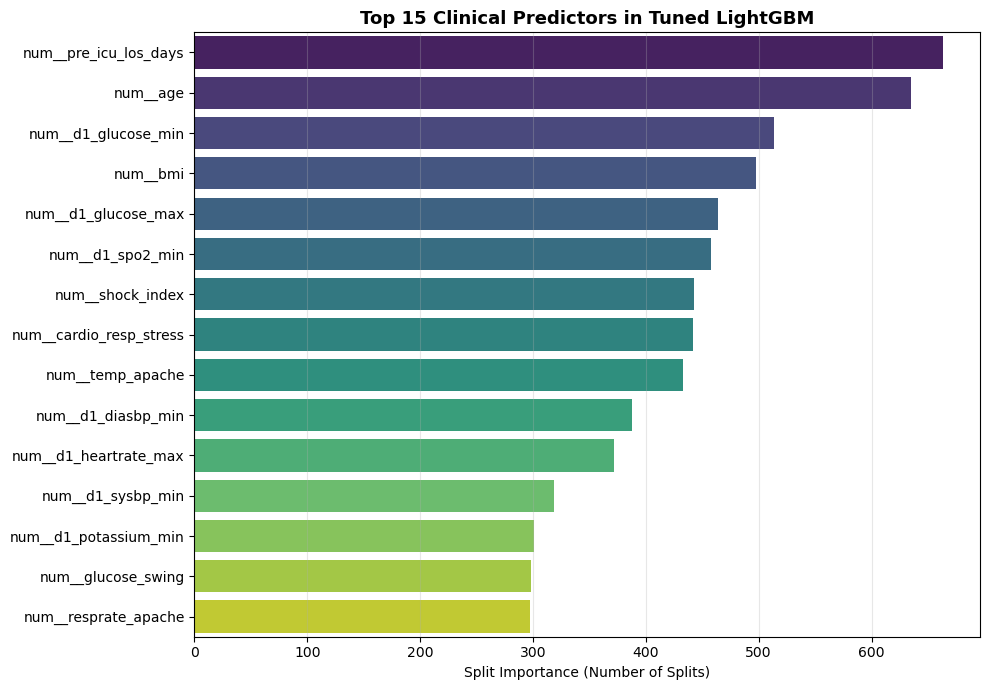

In [171]:
# Plot Top 15 Most Important Features
plt.figure(figsize=(10, 7))
sns.barplot(data=feat_imp_df.head(15), x="Importance", y="Feature", palette="viridis", hue="Feature", legend=False)
plt.title("Top 15 Clinical Predictors in Tuned LightGBM", fontsize=13, fontweight="bold")
plt.xlabel("Split Importance (Number of Splits)")
plt.ylabel("")
plt.grid(axis="x", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "assets/figures/feature_importance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


## Final Holdout Test-Set Evaluation (ROC Curve, PR Curve & Confusion Matrix)

In [101]:
from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    RocCurveDisplay, PrecisionRecallDisplay,
    classification_report, confusion_matrix
)

final_model = random_search.best_estimator_

# Separate test predictors and test target labels from strat_test_set
X_test = strat_test_set.drop("hospital_death", axis=1)
y_test = strat_test_set["hospital_death"].copy()

y_test_probs = final_model.predict_proba(X_test)[:, 1]
y_test_preds = final_model.predict(X_test)

In [102]:
print(f"Final Test ROC-AUC: {roc_auc_score(y_test, y_test_probs):.4f}")

Final Test ROC-AUC: 0.8780


In [103]:
print(f"Final Test PR-AUC:  {average_precision_score(y_test, y_test_probs):.4f}\n")

Final Test PR-AUC:  0.5038



In [104]:
print("Classification Report (Default 0.50 Threshold):")
print(classification_report(y_test, y_test_preds, target_names=["Survived (0)", "Died (1)"]))

Classification Report (Default 0.50 Threshold):
              precision    recall  f1-score   support

Survived (0)       0.97      0.80      0.88     16760
    Died (1)       0.27      0.78      0.40      1583

    accuracy                           0.80     18343
   macro avg       0.62      0.79      0.64     18343
weighted avg       0.91      0.80      0.84     18343



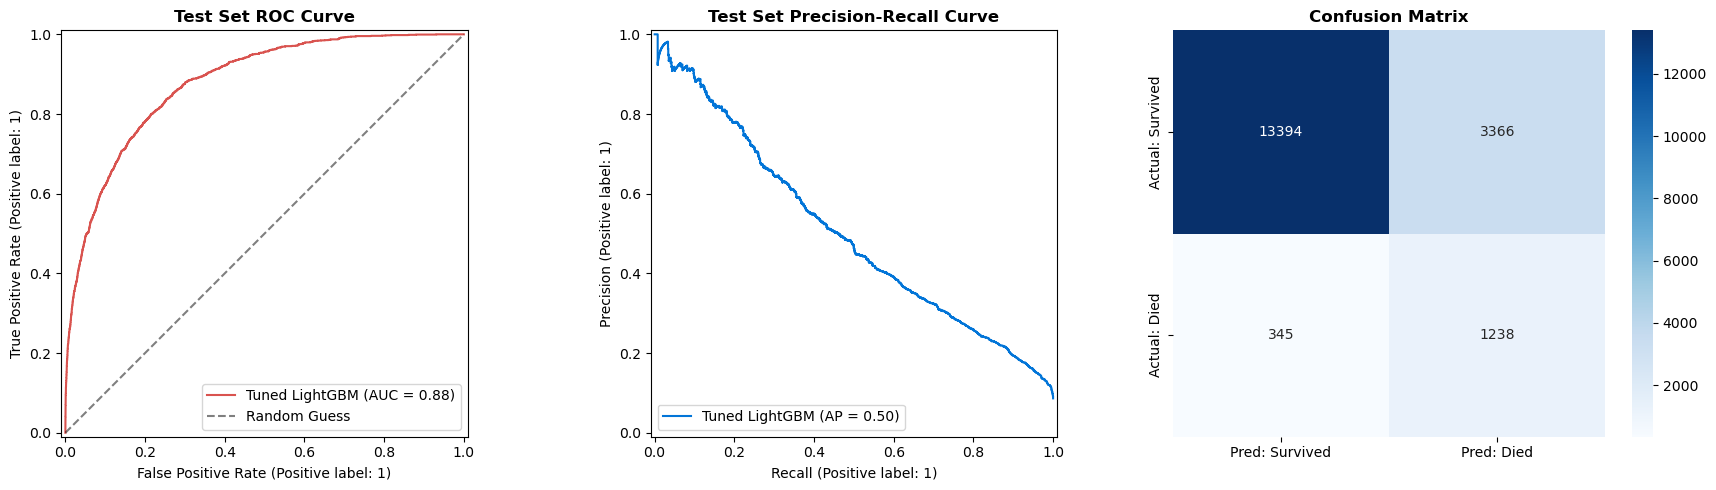

In [173]:
# Plot ROC Curve, Precision-Recall Curve, and Confusion Matrix side-by-side
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

RocCurveDisplay.from_predictions(y_test, y_test_probs, ax=axes[0], name="Tuned LightGBM", color="#d9534f")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.5, label="Random Guess")
axes[0].set_title("Test Set ROC Curve", fontweight="bold")
axes[0].legend()

PrecisionRecallDisplay.from_predictions(y_test, y_test_probs, ax=axes[1], name="Tuned LightGBM", color="#0275d8")
axes[1].set_title("Test Set Precision-Recall Curve", fontweight="bold")

cm = confusion_matrix(y_test, y_test_preds)
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=["Pred: Survived", "Pred: Died"],
            yticklabels=["Actual: Survived", "Actual: Died"], ax=axes[2])
axes[2].set_title("Confusion Matrix", fontweight="bold")

plt.tight_layout()

fig.savefig(
    "assets/figures/test_evaluation.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

In [106]:
feat_imp_df.head(15)

,Feature,Importance
2,num__pre_icu_los_days,663
0,num__age,635
13,num__d1_glucose_min,514
1,num__bmi,498
12,num__d1_glucose_max,464
10,num__d1_spo2_min,458
16,num__shock_index,443
21,num__cardio_resp_stress,442
7,num__temp_apache,433
8,num__d1_diasbp_min,388


## Reusable Prediction Function

In [108]:
def predict_mortality_risk(config, model):
    """Predict in-hospital mortality probability for one or more ICU patients.

    Parameters
    ----------
    config : dict or pandas.DataFrame
        Patient vitals, labs, and demographics. Dictionary values should be
        sequences for batch input.
    model : fitted sklearn.pipeline.Pipeline
        End-to-end preprocessing and classification pipeline.

    Returns
    -------
    numpy.ndarray
        Predicted probability of in-hospital mortality (0.0 to 1.0) for each patient.
    """
    if isinstance(config, dict):
        df = pd.DataFrame(config)
    else:
        df = config.copy()

    # model already includes SimpleImputer, BiomedicalAttrAdder, Scaler, and OneHotEncoder
    return model.predict_proba(df)[:, 1]


## Model Serialization

In [110]:
import pickle

with open("icu_mortality_model.bin", "wb") as f_out:
    pickle.dump(final_model, f_out)


In [111]:
with open("icu_mortality_model.bin", "rb") as f_in:
    icu_mortality_model = pickle.load(f_in)

In [169]:
from pathlib import Path

Path("assets/figures").mkdir(parents=True, exist_ok=True)